Tahreem Junaid 247041

# Lab Task 2



**Task # 01:**

### Lab Task: Affine Transformation Order

Apply **scaling, rotation, and translation** to the given image using a single \(3\times3\) affine transformation matrix. Perform the transformations in the following three different orders:
- **Scaling → Rotation → Translation**
- **Rotation → Scaling → Translation**, and
- **Translation → Rotation → Scaling**.

Display the three resulting images side by side and compare them.

Observe whether changing the order of the transformations changes the final output. Based on your results, explain why the order of matrix multiplication affects the final transformed image.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
print("OpenCV:", cv2.__version__)

OpenCV: 4.14.0


In [ ]:
image_path = "ss.png"
img = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

In [ ]:
# Image dimensions
h, w = img_rgb.shape[:2]

In [ ]:
# Transformation values
scale = 1.2
angle = np.deg2rad(25)
tx = 100
ty = 50

In [ ]:
#  Scaling matrix
A_scale = np.array([
    [scale, 0, 0],
    [0, scale, 0],
    [0, 0, 1]
], dtype=float)

In [ ]:
#  Rotation matrix
A_rotate = np.array([
    [np.cos(angle), -np.sin(angle), 0],
    [np.sin(angle),  np.cos(angle), 0],
    [0, 0, 1]
], dtype=float)


In [ ]:
# Translation matrix
A_translate = np.array([
    [1, 0, tx],
    [0, 1, ty],
    [0, 0, 1]
], dtype=float)

In [ ]:
# order 1:
# Scaling -> Rotation -> Translation
A1 = A_translate @ A_rotate @ A_scale

M1 = A1[:2, :]

result1 = cv2.warpAffine(
    img_rgb,
    M1,
    (w, h)
)

In [ ]:
# order 2:
# Rotation -> Scaling -> Translation
A2 = A_translate @ A_scale @ A_rotate
M2 = A2[:2, :]

result2 = cv2.warpAffine(
    img_rgb,
    M2,
    (w, h)
)

In [ ]:
# order 3:
# Translation -> Rotation -> Scaling
A3 = A_scale @ A_rotate @ A_translate

M3 = A3[:2, :]

result3 = cv2.warpAffine(
    img_rgb,
    M3,
    (w, h)
)

In [ ]:
print("ORDER 1:\n Scaling -> Rotation -> Translation")
print(A1)

print("\nOrder 2: \nRotation -> Scaling -> Translation")
print(A2)

print("\nOrder 3: \nTranslation -> Rotation -> Scaling")
print(A3)

ORDER 1:
 Scaling -> Rotation -> Translation
[[  1.088  -0.507 100.   ]
 [  0.507   1.088  50.   ]
 [  0.      0.      1.   ]]

Order 2: 
Rotation -> Scaling -> Translation
[[  1.088  -0.507 100.   ]
 [  0.507   1.088  50.   ]
 [  0.      0.      1.   ]]

Order 3: 
Translation -> Rotation -> Scaling
[[  1.088  -0.507  83.4  ]
 [  0.507   1.088 105.093]
 [  0.      0.      1.   ]]


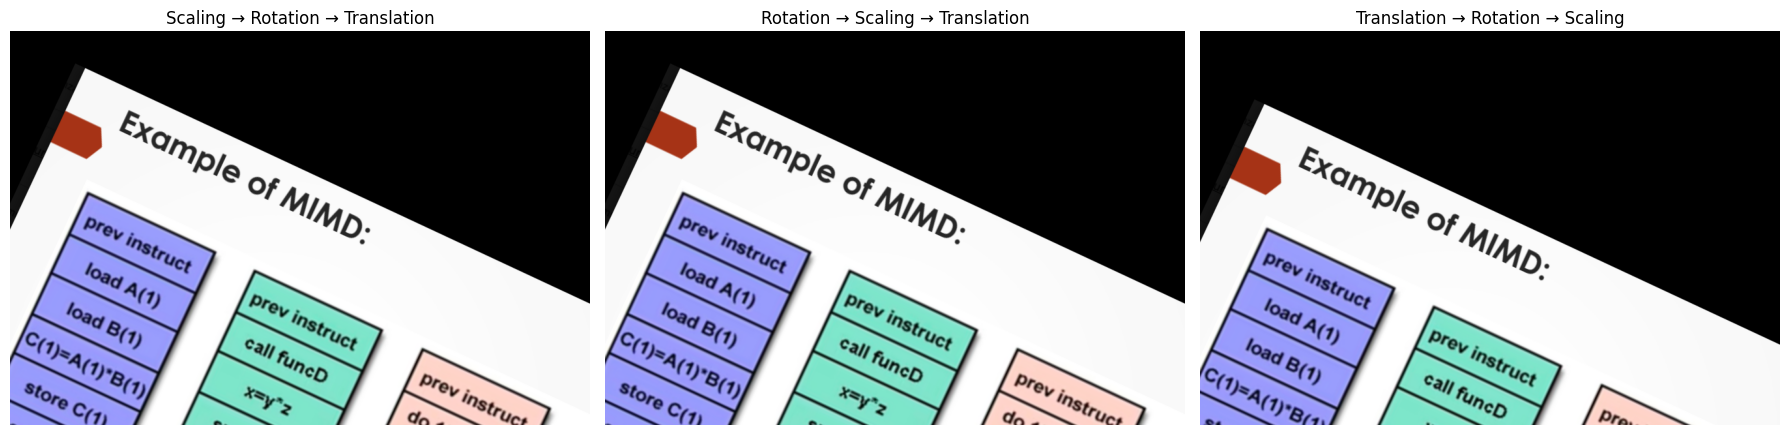

In [ ]:
#display all three results
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(result1)
axes[0].set_title("Scaling → Rotation → Translation")
axes[0].axis("off")

axes[1].imshow(result2)
axes[1].set_title("Rotation → Scaling → Translation")
axes[1].axis("off")

axes[2].imshow(result3)
axes[2].set_title("Translation → Rotation → Scaling")
axes[2].axis("off")

plt.tight_layout()
plt.show()

**Task # 02:**

Apply image scaling using different interpolation techniques available in OpenCV. Scale the given image up by 2× and compare the results obtained using INTER_NEAREST, INTER_LINEAR, INTER_CUBIC, and INTER_LANCZOS4. Display the original image and all scaled versions together, then compare the images by observing differences in sharpness, smoothness, pixelation, and preservation of fine details. Also print the resulting image dimensions for each interpolation method and briefly state which interpolation method produces the most visually suitable result for upscaling and why.

In [ ]:
# Get dimensions
h, w = img_rgb.shape[:2]

In [ ]:
# Scale image using different interpolation methods

scaled_nearest = cv2.resize(
    img_rgb,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_NEAREST
)

scaled_linear = cv2.resize(
    img_rgb,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_LINEAR
)

scaled_cubic = cv2.resize(
    img_rgb,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_CUBIC
)

scaled_lanczos = cv2.resize(
    img_rgb,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_LANCZOS4
)

In [ ]:
# Print dimensions

print("Original image dimensions:", w, "×", h)

print("INTER_NEAREST dimensions:",
      scaled_nearest.shape[1], "×", scaled_nearest.shape[0])

print("INTER_LINEAR dimensions:",
      scaled_linear.shape[1], "×", scaled_linear.shape[0])

print("INTER_CUBIC dimensions:",
      scaled_cubic.shape[1], "×", scaled_cubic.shape[0])

print("INTER_LANCZOS4 dimensions:",
      scaled_lanczos.shape[1], "×", scaled_lanczos.shape[0])

Original image dimensions: 890 × 604
INTER_NEAREST dimensions: 1780 × 1208
INTER_LINEAR dimensions: 1780 × 1208
INTER_CUBIC dimensions: 1780 × 1208
INTER_LANCZOS4 dimensions: 1780 × 1208


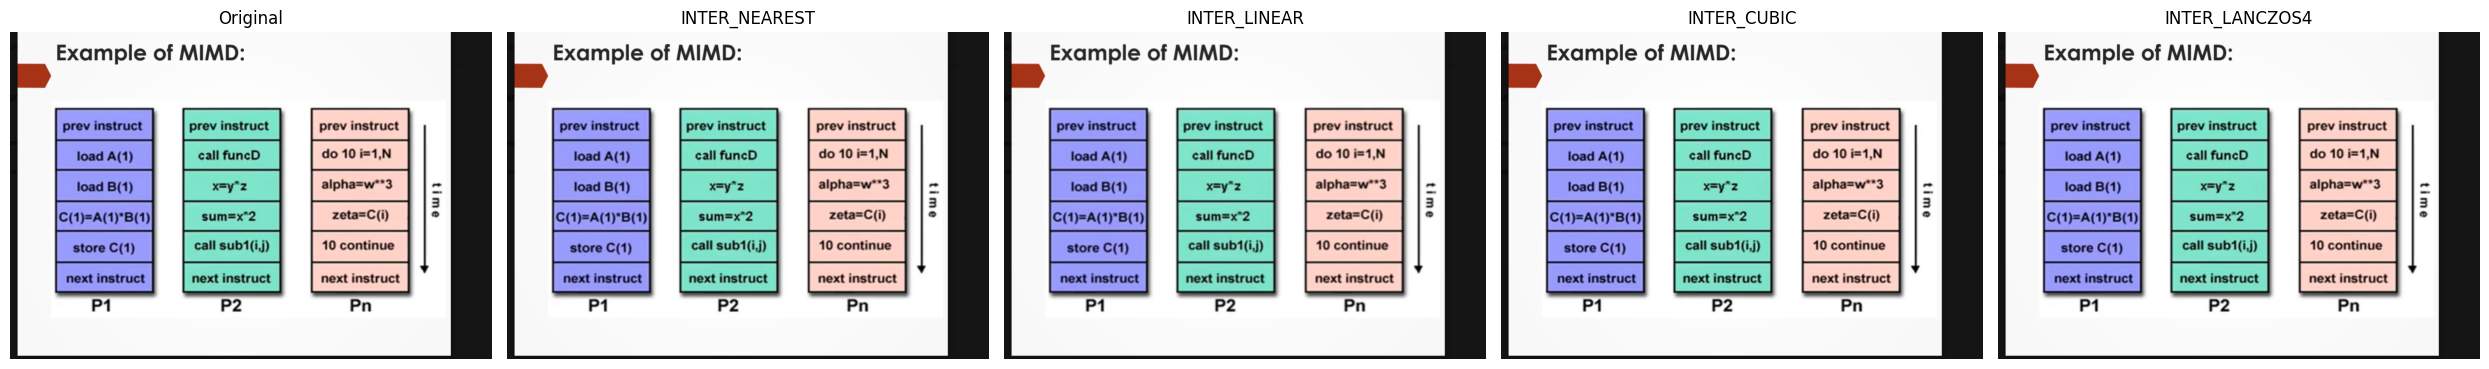

In [ ]:
# Display all images

fig, axes = plt.subplots(1, 5, figsize=(25, 6))

axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(scaled_nearest)
axes[1].set_title("INTER_NEAREST")
axes[1].axis("off")

axes[2].imshow(scaled_linear)
axes[2].set_title("INTER_LINEAR")
axes[2].axis("off")

axes[3].imshow(scaled_cubic)
axes[3].set_title("INTER_CUBIC")
axes[3].axis("off")

axes[4].imshow(scaled_lanczos)
axes[4].set_title("INTER_LANCZOS4")
axes[4].axis("off")

plt.tight_layout()
plt.show()

**Task # 03:**

Use any image and apply a homography transformation to change its perspective. Select four points from the image and map them to four new points to create a perspective-distorted or perspective-corrected image. Use cv2.getPerspectiveTransform() to calculate the homography matrix and cv2.warpPerspective() to apply it. Display the original and transformed images and observe how the perspective of the image changes.

In [ ]:
# Get image dimensions
h, w = img_rgb.shape[:2]

In [ ]:
# Select four points from the original image

src = np.float32([
    [120, 100],
    [520, 100],
    [520, 360],
    [120, 360]
])

dst = np.float32([
    [170, 70],
    [560, 130],
    [480, 390],
    [90, 330]
])

In [ ]:
# Calculate homography matrix

H = cv2.getPerspectiveTransform(src, dst)

print("Homography Matrix:")
print(H)

Homography Matrix:
[[  0.975  -0.308  83.769]
 [  0.15    1.    -48.   ]
 [  0.      0.      1.   ]]


In [ ]:
# Apply homography

homography_img = cv2.warpPerspective(
    img_rgb,
    H,
    (w, h)
)

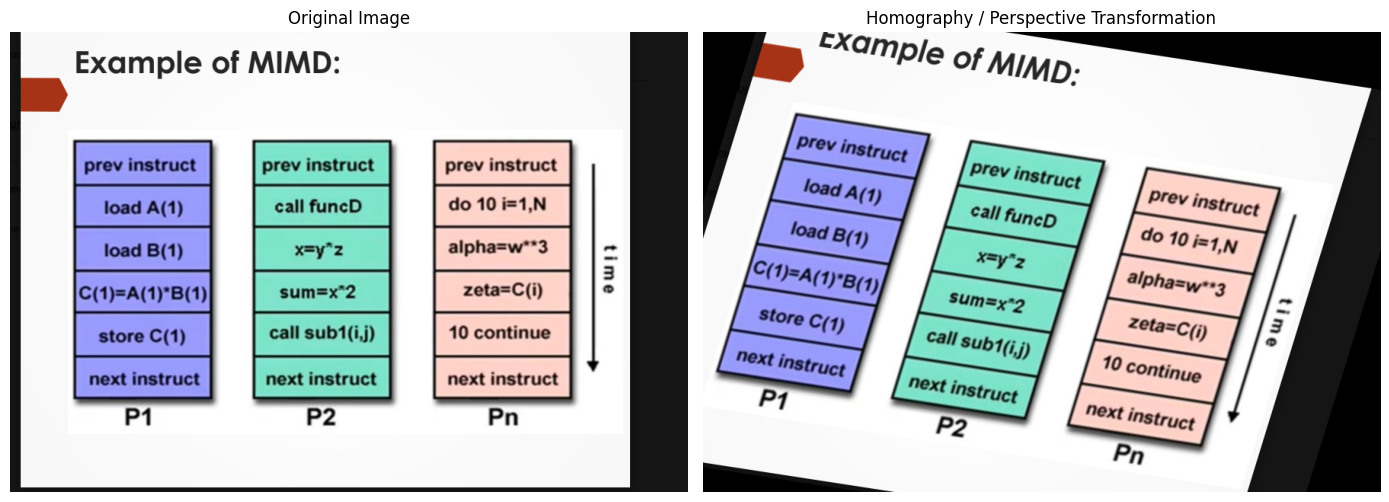

In [ ]:
# Display original and transformed images

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(img_rgb)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(homography_img)
axes[1].set_title("Homography / Perspective Transformation")
axes[1].axis("off")

plt.tight_layout()
plt.show()